# Polynomial Regression with Gradient Descent Optimizers

In [1]:
import time
from collections.abc import Callable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures

## 1. Generate the data

In [2]:
np.random.seed(42)

x1 = np.random.rand(100)
x2 = np.random.rand(100)


def polynomial(x1: np.ndarray, x2: np.ndarray) -> np.ndarray:
  return 4 * x1**2 + 5 * x2**2 - 2 * x1 * x2 + 3 * x1 - 6 * x2


X_raw = np.column_stack([x1, x2])
y = polynomial(x1, x2)

print('X shape:', X_raw.shape)
print('y shape:', y.shape)

X shape: (100, 2)
y shape: (100,)


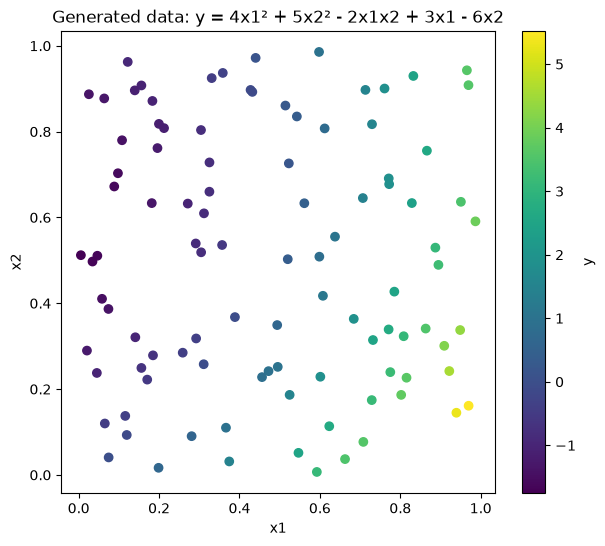

In [6]:
fig, ax = plt.subplots(figsize=(7, 6))
points = ax.scatter(x1, x2, c=y, cmap='viridis')
fig.colorbar(points, label='y')
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_title('Generated data: y = 4x1² + 5x2² - 2x1x2 + 3x1 - 6x2')
plt.show()

## 2. Polynomial features

In [7]:
poly = PolynomialFeatures(degree=2)
X = poly.fit_transform(X_raw)
feature_names = list(poly.get_feature_names_out(['x1', 'x2']))
true_weights = np.array([0, 3, -6, 4, -2, 5])

print('X shape:', X.shape)
pd.DataFrame(X, columns=feature_names).head()

X shape: (100, 6)


,1,x1,x2,x1^2,x1 x2,x2^2
0,1.0,0.374540,0.031429,0.140280,0.011771,0.000988
1,1.0,0.950714,0.636410,0.903858,0.605044,0.405018
2,1.0,0.731994,0.314356,0.535815,0.230107,0.098820
3,1.0,0.598658,0.508571,0.358392,0.304460,0.258644
4,1.0,0.156019,0.907566,0.024342,0.141597,0.823677


In [9]:
exact_weights = np.linalg.lstsq(X, y, rcond=None)[0]

pd.DataFrame({'true': true_weights, 'least squares': exact_weights.round(6)}, index=feature_names)

,true,least squares
1,0,-0.0
x1,3,3.0
x2,-6,-6.0
x1^2,4,4.0
x1 x2,-2,-2.0
x2^2,5,5.0


## 3. Gradient descent variants

In [10]:
def mse(X: np.ndarray, y: np.ndarray, weights: np.ndarray) -> float:
  return float(np.mean((X @ weights - y) ** 2))


def mse_gradient(X: np.ndarray, y: np.ndarray, weights: np.ndarray) -> np.ndarray:
  return 2 / len(y) * X.T @ (X @ weights - y)

In [13]:
def polynomial_regression_gradient_descent(
  X: np.ndarray,
  y: np.ndarray,
  learning_rate: float = 0.5,
  n_iter: int = 1000,
  tol: float = 0.0,
) -> tuple[np.ndarray, list[float]]:
  weights = np.zeros(X.shape[1])
  history = []

  for _ in range(n_iter):
    weights = weights - learning_rate * mse_gradient(X, y, weights)
    history.append(mse(X, y, weights))
    if history[-1] < tol:
      break

  return weights, history

In [17]:
def polynomial_regression_SGD(
  X: np.ndarray,
  y: np.ndarray,
  learning_rate: float = 0.2,
  n_iter: int = 1000,
  batch_size: int = 10,
  tol: float = 0.0,
  seed: int = 42,
) -> tuple[np.ndarray, list[float]]:
  rng = np.random.default_rng(seed)
  weights = np.zeros(X.shape[1])
  history = []

  for _ in range(n_iter):
    batch = rng.integers(0, len(y), batch_size)
    weights = weights - learning_rate * mse_gradient(X[batch], y[batch], weights)
    history.append(mse(X, y, weights))
    if history[-1] < tol:
      break

  return weights, history

In [20]:
def polynomial_regression_rmsprop(
  X: np.ndarray,
  y: np.ndarray,
  learning_rate: float = 0.01,
  n_iter: int = 1000,
  beta: float = 0.9,
  eps: float = 1e-8,
  tol: float = 0.0,
) -> tuple[np.ndarray, list[float]]:
  weights = np.zeros(X.shape[1])
  squared_avg = np.zeros(X.shape[1])
  history = []

  for _ in range(n_iter):
    gradient = mse_gradient(X, y, weights)
    squared_avg = beta * squared_avg + (1 - beta) * gradient**2
    weights = weights - learning_rate * gradient / (np.sqrt(squared_avg) + eps)
    history.append(mse(X, y, weights))
    if history[-1] < tol:
      break

  return weights, history

In [22]:
def polynomial_regression_adam(
  X: np.ndarray,
  y: np.ndarray,
  learning_rate: float = 0.1,
  n_iter: int = 1000,
  beta1: float = 0.9,
  beta2: float = 0.999,
  eps: float = 1e-8,
  tol: float = 0.0,
) -> tuple[np.ndarray, list[float]]:
  weights = np.zeros(X.shape[1])
  m = np.zeros(X.shape[1])
  v = np.zeros(X.shape[1])
  history = []

  for t in range(1, n_iter + 1):
    gradient = mse_gradient(X, y, weights)
    m = beta1 * m + (1 - beta1) * gradient
    v = beta2 * v + (1 - beta2) * gradient**2
    m_hat = m / (1 - beta1**t)
    v_hat = v / (1 - beta2**t)
    weights = weights - learning_rate * m_hat / (np.sqrt(v_hat) + eps)
    history.append(mse(X, y, weights))
    if history[-1] < tol:
      break

  return weights, history

In [24]:
def polynomial_regression_nadam(
  X: np.ndarray,
  y: np.ndarray,
  learning_rate: float = 0.1,
  n_iter: int = 1000,
  beta1: float = 0.9,
  beta2: float = 0.999,
  eps: float = 1e-8,
  tol: float = 0.0,
) -> tuple[np.ndarray, list[float]]:
  weights = np.zeros(X.shape[1])
  m = np.zeros(X.shape[1])
  v = np.zeros(X.shape[1])
  history = []

  for t in range(1, n_iter + 1):
    gradient = mse_gradient(X, y, weights)
    m = beta1 * m + (1 - beta1) * gradient
    v = beta2 * v + (1 - beta2) * gradient**2
    m_hat = m / (1 - beta1**t)
    v_hat = v / (1 - beta2**t)
    nesterov_m = beta1 * m_hat + (1 - beta1) * gradient / (1 - beta1**t)
    weights = weights - learning_rate * nesterov_m / (np.sqrt(v_hat) + eps)
    history.append(mse(X, y, weights))
    if history[-1] < tol:
      break

  return weights, history

In [29]:
methods: dict[str, Callable[..., tuple[np.ndarray, list[float]]]] = {
  'GD': polynomial_regression_gradient_descent,
  'SGD': polynomial_regression_SGD,
  'RMSProp': polynomial_regression_rmsprop,
  'Adam': polynomial_regression_adam,
  'Nadam': polynomial_regression_nadam,
}

rows = []
for name, method in methods.items():
  weights, history = method(X, y)
  rows.append({'method': name, 'MSE after 1000 iterations': history[-1], **dict(zip(feature_names, weights.round(3)))})

pd.DataFrame(rows).set_index('method')

,MSE after 1000 iterations,1,x1,x2,x1^2,x1 x2,x2^2
method,,,,,,,
GD,0.001295,-0.132,3.175,-5.455,3.870,-2.100,4.523
SGD,0.021304,-0.406,3.220,-3.970,3.722,-1.960,2.993
RMSProp,0.002044,-0.155,3.142,-5.349,3.903,-2.124,4.424
Adam,0.000005,-0.009,3.031,-5.980,3.973,-2.008,4.984
Nadam,0.000001,-0.004,3.016,-5.994,3.986,-2.003,4.995


## 4. Running time with %timeit

In [30]:
%timeit -r 5 -n 10 polynomial_regression_gradient_descent(X, y, n_iter=1000)

3.8 ms ± 48.2 μs per loop (mean ± std. dev. of 5 runs, 10 loops each)


In [31]:
%timeit -r 5 -n 10 polynomial_regression_SGD(X, y, n_iter=1000)

6.98 ms ± 55.9 μs per loop (mean ± std. dev. of 5 runs, 10 loops each)

In [32]:
%timeit -r 5 -n 10 polynomial_regression_rmsprop(X, y, n_iter=1000)

6.66 ms ± 124 μs per loop (mean ± std. dev. of 5 runs, 10 loops each)


In [33]:
%timeit -r 5 -n 10 polynomial_regression_adam(X, y, n_iter=1000)

7.6 ms ± 89.2 μs per loop (mean ± std. dev. of 5 runs, 10 loops each)


In [34]:
%timeit -r 5 -n 10 polynomial_regression_nadam(X, y, n_iter=1000)

8.77 ms ± 169 μs per loop (mean ± std. dev. of 5 runs, 10 loops each)


## 5. Choosing the optimal number of iterations

In [57]:
TOL = 1e-4
MAX_ITER = 50_000

learning_rates = {
  'GD': [0.05, 0.1, 0.3, 0.5, 0.6],
  'SGD': [0.02, 0.05, 0.1, 0.2, 0.3],
  'RMSProp': [0.0005, 0.001, 0.005, 0.01],
  'Adam': [0.01, 0.05, 0.1, 0.3, 0.5, 1.0],
  'Nadam': [0.01, 0.05, 0.1, 0.3, 0.5, 1.0],
}

search_rows = []
for name, method in methods.items():
  for lr in learning_rates[name]:
    with np.errstate(over='ignore', invalid='ignore'):
      _, history = method(X, y, learning_rate=lr, n_iter=MAX_ITER, tol=TOL)
    search_rows.append({
      'method': name,
      'learning_rate': lr,
      'iterations': len(history),
      'final MSE': history[-1],
      'converged': history[-1] < TOL,
    })

search = pd.DataFrame(search_rows)
search

,method,learning_rate,iterations,final MSE,converged
0,GD,0.0500,15959,0.000100,True
1,GD,0.1000,7979,0.000100,True
2,GD,0.3000,2659,0.000100,True
3,GD,0.5000,1595,0.000100,True
4,GD,0.6000,50000,NaN,False
5,SGD,0.0200,39879,0.000100,True
6,SGD,0.0500,15919,0.000100,True
7,SGD,0.1000,7938,0.000100,True
8,SGD,0.2000,3982,0.000098,True
9,SGD,0.3000,2641,0.000100,True


In [59]:
ranked = search.sort_values('iterations')
best = ranked[ranked['converged']].groupby('method').head(1).set_index('method')
best

,learning_rate,iterations,final MSE,converged
method,,,,
Adam,1.000,251,0.000096,True
Nadam,0.500,311,0.000098,True
GD,0.500,1595,0.000100,True
RMSProp,0.005,2270,0.000100,True
SGD,0.300,2641,0.000100,True


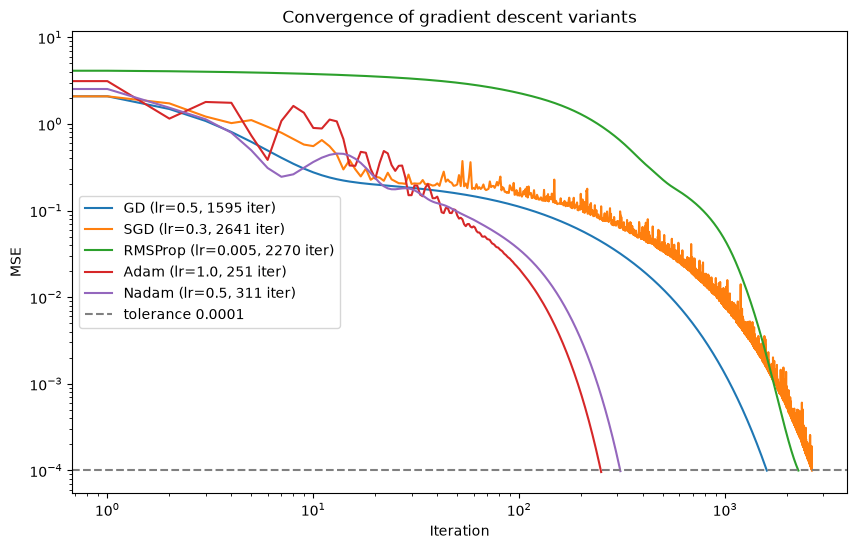

In [70]:
fig, ax = plt.subplots(figsize=(10, 6))

for name, method in methods.items():
  lr = float(best.loc[name, 'learning_rate'])
  _, history = method(X, y, learning_rate=lr, n_iter=MAX_ITER, tol=TOL)
  ax.plot(history, label=f'{name} (lr={lr}, {len(history)} iter)')

ax.axhline(TOL, color='gray', linestyle='--', label=f'tolerance {TOL}')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Iteration')
ax.set_ylabel('MSE')
ax.set_title('Convergence of gradient descent variants')
ax.legend()
plt.show()

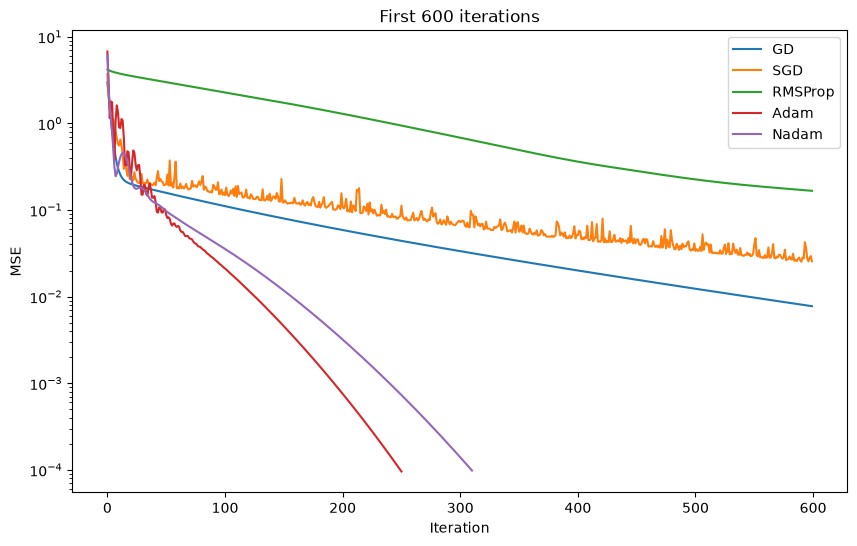

In [73]:
fig, ax = plt.subplots(figsize=(10, 6))

for name, method in methods.items():
  lr = float(best.loc[name, 'learning_rate'])
  _, history = method(X, y, learning_rate=lr, n_iter=MAX_ITER, tol=TOL)
  ax.plot(history[:600], label=name)

ax.set_yscale('log')
ax.set_xlabel('Iteration')
ax.set_ylabel('MSE')
ax.set_title('First 600 iterations')
ax.legend()
plt.show()

## 6. Running time with the optimal settings

In [75]:
optimal = {name: (float(best.loc[name, 'learning_rate']), int(best.loc[name, 'iterations'])) for name in methods}
optimal

{'GD': (0.5, 1595),
 'SGD': (0.3, 2641),
 'RMSProp': (0.005, 2270),
 'Adam': (1.0, 251),
 'Nadam': (0.5, 311)}

In [76]:
lr, n = optimal['GD']
%timeit -r 5 -n 10 polynomial_regression_gradient_descent(X, y, learning_rate=lr, n_iter=n)

6.17 ms ± 27.8 μs per loop (mean ± std. dev. of 5 runs, 10 loops each)


In [77]:
lr, n = optimal['SGD']
%timeit -r 5 -n 10 polynomial_regression_SGD(X, y, learning_rate=lr, n_iter=n)

16.1 ms ± 1.22 ms per loop (mean ± std. dev. of 5 runs, 10 loops each)


In [78]:
lr, n = optimal['RMSProp']
%timeit -r 5 -n 3 polynomial_regression_rmsprop(X, y, learning_rate=lr, n_iter=n)

15.1 ms ± 254 μs per loop (mean ± std. dev. of 5 runs, 3 loops each)


In [79]:
lr, n = optimal['Adam']
%timeit -r 5 -n 10 polynomial_regression_adam(X, y, learning_rate=lr, n_iter=n)

1.98 ms ± 64 μs per loop (mean ± std. dev. of 5 runs, 10 loops each)


In [80]:
lr, n = optimal['Nadam']
%timeit -r 5 -n 10 polynomial_regression_nadam(X, y, learning_rate=lr, n_iter=n)

2.85 ms ± 341 μs per loop (mean ± std. dev. of 5 runs, 10 loops each)


In [86]:
def measure_seconds(method: Callable[..., tuple[np.ndarray, list[float]]], repeats: int = 5, **kwargs: float) -> float:
  timings = []
  for _ in range(repeats):
    start = time.perf_counter()
    method(X, y, **kwargs)
    timings.append(time.perf_counter() - start)

  return min(timings)


summary_rows = []
for name, method in methods.items():
  lr, n = optimal[name]
  weights, history = method(X, y, learning_rate=lr, n_iter=n)
  seconds = measure_seconds(method, learning_rate=lr, n_iter=n)
  summary_rows.append({
    'method': name,
    'learning_rate': lr,
    'iterations': n,
    'total time, ms': seconds * 1000,
    'time per iteration, µs': seconds / n * 1e6,
    'final MSE': history[-1],
    'max |w - w_true|': np.abs(weights - true_weights).max(),
  })

summary = pd.DataFrame(summary_rows).set_index('method')
summary.round(4)

,learning_rate,iterations,"total time, ms","time per iteration, µs",final MSE,max |w - w_true|
method,,,,,,
GD,0.500,1595,6.2627,3.9265,0.0001,0.1472
SGD,0.300,2641,15.0535,5.6999,0.0001,0.1480
RMSProp,0.005,2270,11.8915,5.2385,0.0001,0.0948
Adam,1.000,251,1.8705,7.4520,0.0001,0.1416
Nadam,0.500,311,2.2793,7.3290,0.0001,0.1454


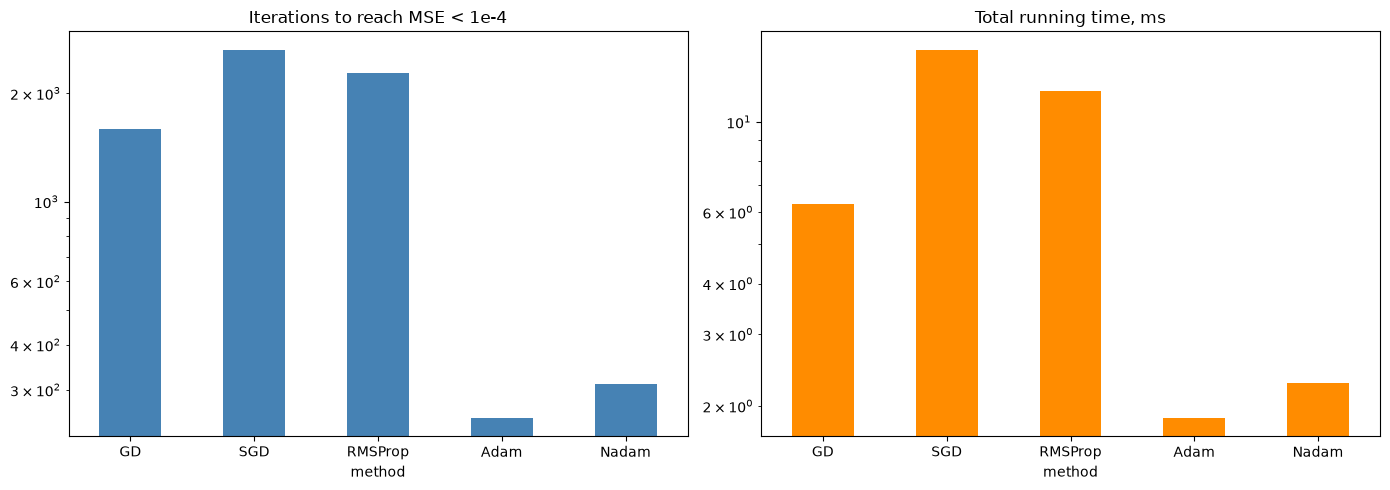

In [90]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

summary['iterations'].plot.bar(ax=axes[0], color='steelblue')
axes[0].set_yscale('log')
axes[0].set_title('Iterations to reach MSE < 1e-4')

summary['total time, ms'].plot.bar(ax=axes[1], color='darkorange')
axes[1].set_yscale('log')
axes[1].set_title('Total running time, ms')

for ax in axes:
  ax.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

## Conclusion

- All five optimizers recover the true coefficients (0, 3, -6, 4, -2, 5), which least squares also gives exactly.
- With a fixed budget of 1000 iterations, Adam and Nadam are already at MSE ~1e-6, while GD, RMSProp and SGD are still at 1e-3 to 2e-2.
- Iterations needed to reach MSE < 1e-4 with the best learning rate: Adam 251, Nadam 311, GD 1595, RMSProp 2270, SGD 2641.
- In wall-clock time Adam (~2 ms) and Nadam (~2.3 ms) win too: each iteration costs about 2x more than plain GD, but they need 5-10x fewer iterations.
- Plain GD is the cheapest per iteration (~4 µs) but is capped by stability: lr = 0.5 works, lr = 0.6 diverges, because the largest Hessian eigenvalue is ~3.6.
- SGD with mini-batches of 10 needs the most iterations and is noisy; on 100 samples a full-batch gradient is so cheap that the sampling overhead makes SGD slower per iteration than GD.
- RMSProp with a constant learning rate stalls at a noise floor that depends on lr: with lr = 0.01 it never gets below MSE 2e-4 in 50,000 iterations, so it needs a small step.
- MSE < 1e-4 still leaves coefficient errors of ~0.1-0.15: the features x1, x1², x1x2 are strongly correlated, the problem is ill-conditioned and the last digits converge slowly for every method.
- Overall, Adam/Nadam are the most efficient choice here; plain GD is a reasonable baseline when the learning rate is tuned close to its stability limit.